# Explicación del modelo con SHAP

Resultados del prototipo: qué respuestas pesan más en el modelo ganador (XGBoost) y cómo se explica el resultado de una persona. El código está en `bolsalab/explain.py` y `bolsalab/modeling/predict.py`; las decisiones, en `docs/prototipo.md` y en la sección 8 del protocolo.

Antes de correrlo: `uv run python -m bolsalab.modeling.train --prototype` y `uv run python -m bolsalab.explain`.

In [1]:
import pandas as pd
import shap
from IPython.display import Image

from bolsalab.config import FIGURES_DIR
from bolsalab.explain import GLOBAL_FILE, NAMES
from bolsalab.features import TRAINING_FILE
from bolsalab.modeling.predict import CrashReactionModel, build_features
from bolsalab.modeling.train import split_data

model = CrashReactionModel()
print('Ganador:', model.metadata['winner'], model.metadata['params'])
print('Cortes de las categorías:', [round(c, 3) for c in model.metadata['cutoffs']])

c:\Repos\bolsalab\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ganador: xgboost {'model__learning_rate': 0.03, 'model__max_depth': 3}
Cortes de las categorías: [0.159, 0.221]


## Qué respuestas pesan más

Peso medio de cada respuesta (|SHAP| promedio) en 5.000 personas del entrenamiento. La dirección es la correlación entre la respuesta y su aporte: positiva si valores más altos suben la venta.

In [2]:
pd.read_csv(GLOBAL_FILE).round(3)

,variable,nombre,peso_medio,parte_del_total,direccion
0,male,Hombre,0.327,0.279,0.995
1,knows_diversification,Acierta diversificación,0.170,0.145,-0.980
2,knowledge_confidence,Confianza en lo que sabe,0.109,0.093,0.919
3,knows_inflation,Acierta inflación,0.083,0.071,-0.954
4,age,Edad,0.082,0.070,0.648
5,risk_aversion,Aversión al riesgo,0.077,0.066,0.497
6,short_term_view,Visión de corto plazo,0.076,0.065,0.534
7,income_bracket,Tramo de ingreso,0.062,0.053,-0.492
8,knows_interest,Acierta interés compuesto,0.059,0.051,-0.965
9,assets_bracket,Tramo de ahorros e inversiones,0.058,0.050,-0.458


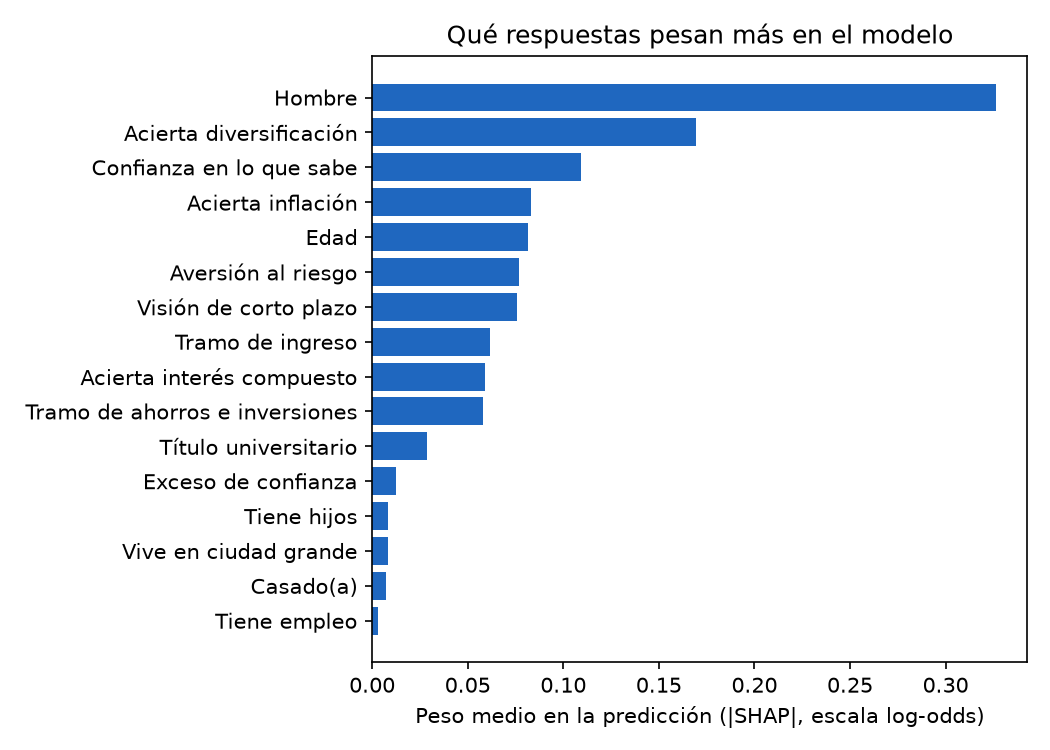

In [4]:
Image(FIGURES_DIR / 'shap_importancia.png', width=600)

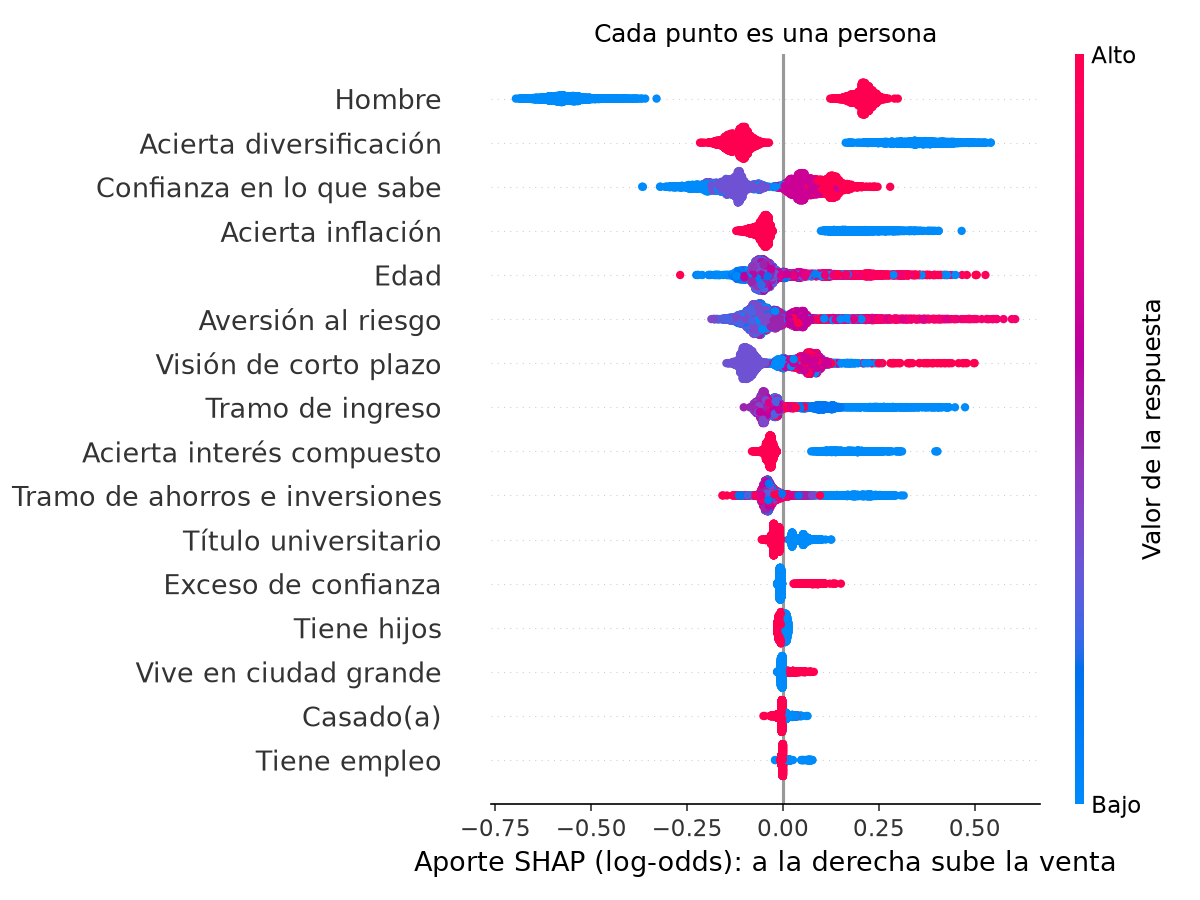

In [5]:
Image(FIGURES_DIR / 'shap_beeswarm.png', width=650)

## ¿El peso del sexo es real?

Es la respuesta que más pesa. Revisamos la tasa de venta en el entrenamiento, y también la del exceso de confianza, que casi no pesa en SHAP.

In [6]:
X_train, _, y_train, _ = split_data(pd.read_parquet(TRAINING_FILE))
rates = X_train.assign(sold=y_train)
for column in ['male', 'overconfidence']:
    display(rates.groupby(column)['sold'].agg(['mean', 'size']).round(3))

,mean,size
male,,
0,0.122,14415
1,0.236,29348


,mean,size
overconfidence,,
0,0.192,40456
1,0.284,3307


Los hombres vendieron casi el doble que las mujeres, así que el peso viene de los datos. Quienes tienen exceso de confianza también vendieron más, pero esa variable se calcula con la confianza y las preguntas de finanzas, y SHAP le reparte su peso a esas dos.

## El resultado de una persona

Una persona de ejemplo, inventada para mostrar la explicación: 27 años, mujer, con título universitario, acierta interés compuesto, no sabe la de inflación, falla diversificación y está totalmente segura de lo que sabe.

In [7]:
answers = {'age': 27, 'male': False, 'university': True, 'married': False, 'has_children': False,
           'urban': True, 'employed': True, 'income_level': 3, 'assets_level': 2,
           'interest': 'more', 'inflation': 'dont_know', 'diversification': 'true',
           'knowledge_confidence': 5}
result = model.predict(answers)
print('Categoría:', result['category'])
pd.DataFrame(result['top_factors'])

Categoría: more_likely


,feature,label,direction,impact,actionable
0,male,Eres mujer,decreases,0.544123,False
1,knows_diversification,No acertaste la pregunta de diversificación,increases,0.507078,True
2,knowledge_confidence,Tu confianza en lo que sabes de finanzas: 5 de 5,increases,0.244926,True
3,knows_inflation,No acertaste la pregunta de inflación,increases,0.242866,True


La gráfica de cascada parte del valor promedio del modelo y suma el aporte de cada respuesta hasta llegar a la predicción de la persona, en log-odds. La app no muestra esta gráfica ni cifras; solo la dirección y el tamaño relativo.

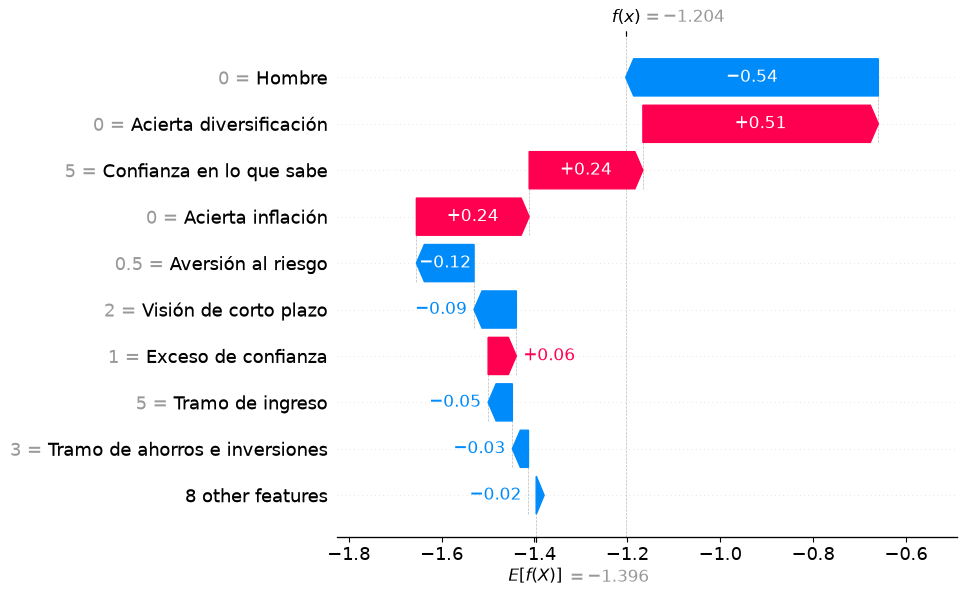

: 

In [ ]:
X = build_features(answers, model.metadata)
explanation = model.explainer(X)
explanation.feature_names = [NAMES.get(c, 'Edad al cuadrado') for c in X.columns]
shap.plots.waterfall(explanation[0], max_display=10)